In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("wdbc.data", sep=",")
columns=['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst']
df.columns=columns

In [3]:
df.sample(5)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
504,915276,B,9.676,13.14,64.12,272.5,0.12550,0.22040,0.11880,0.07038,...,10.60,18.04,69.47,328.1,0.2006,0.3663,0.2913,0.10750,0.2848,0.13640
251,885429,M,19.730,19.82,130.70,1206.0,0.10620,0.18490,0.24170,0.09740,...,25.28,25.59,159.80,1933.0,0.1710,0.5955,0.8489,0.25070,0.2749,0.12970
78,8610908,B,12.860,18.00,83.19,506.3,0.09934,0.09546,0.03889,0.02315,...,14.24,24.82,91.88,622.1,0.1289,0.2141,0.1731,0.07926,0.2779,0.07918
370,9012568,B,15.190,13.21,97.65,711.8,0.07963,0.06934,0.03393,0.02657,...,16.20,15.73,104.50,819.1,0.1126,0.1737,0.1362,0.08178,0.2487,0.06766
387,903011,B,11.270,15.50,73.38,392.0,0.08365,0.11140,0.10070,0.02757,...,12.04,18.93,79.73,450.0,0.1102,0.2809,0.3021,0.08272,0.2157,0.10430


In [4]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()

In [5]:
df['class'] = df['diagnosis'].map({'M':1, 'B':0})
df.drop(['id', 'diagnosis'], axis=1, inplace=True)

In [6]:
sc.fit_transform(df)

array([[ 1.83208378, -0.35832707,  1.68910604, ..., -0.24044363,
         0.28529387,  1.30074714],
       [ 1.58210603,  0.45385958,  1.56958968, ...,  1.16385786,
         0.2053006 ,  1.30074714],
       [-0.76711673,  0.25081292, -0.59077158, ...,  6.08623563,
         4.95045676,  1.30074714],
       ...,
       [ 0.70434323,  2.04789258,  0.6752776 , ..., -1.10613122,
        -0.31576665,  1.30074714],
       [ 1.84060575,  2.33962629,  1.98583632, ...,  1.93516598,
         2.22846365,  1.30074714],
       [-1.80679694,  1.22170271, -1.81313547, ..., -0.04354852,
        -0.74961903, -0.76878893]], shape=(568, 31))

In [7]:
df.to_csv("without_pca.csv",index=False)

NOW I WILL START PCA TO REDUCE NUMBER OF COLUMNS FROM 30 TO ANYTHING LOWER

In [9]:
y=df['class']
df.drop(['class'], axis=1, inplace=True)

<Axes: >

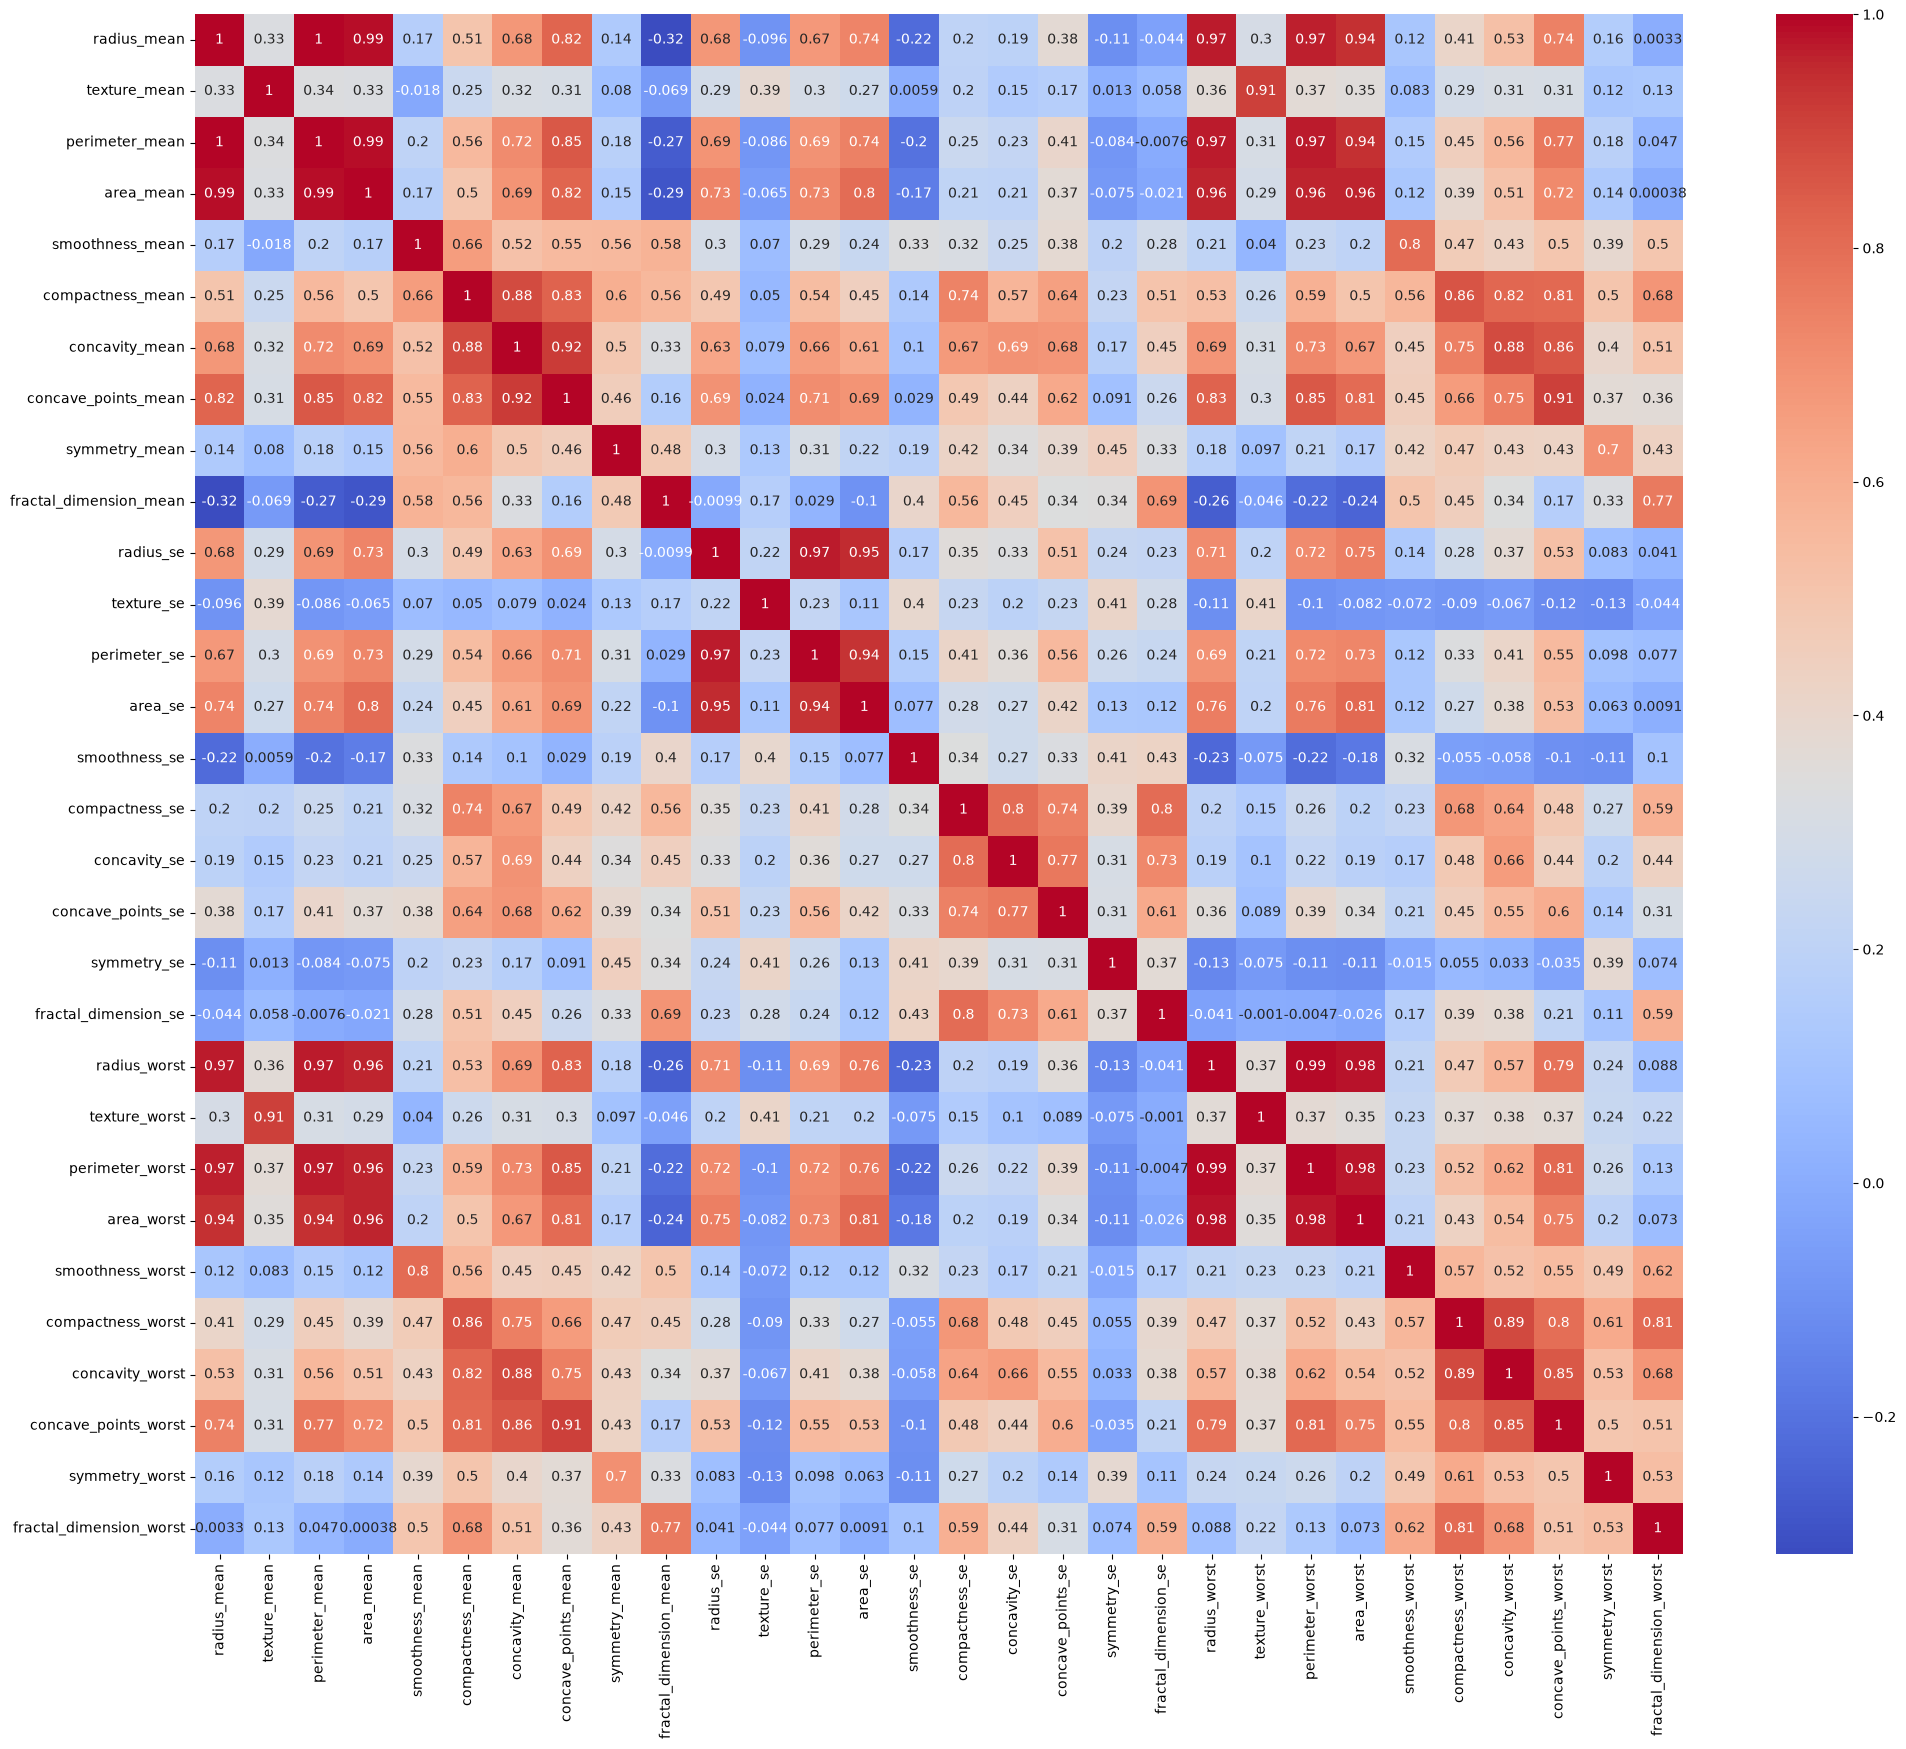

In [10]:
plt.figure(figsize=(24,20))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')

POINTS TO BE NOTED FROM THE CORRELATION HEATMAP
1.PERIMETER_MEAN, AREA_ME AND RADIUS_MEAN ARE COMPLETELY SAME FEATURES SO TWO CAN BE DROPPED
2.PERIMETER_SE, AREA_SE AND RADIUS_SE ARE COMPLETELY SAME FEATURES SO TWO CAN BE DROPPED
3.THE COLUMNS IN THE ABOVE 2 POINTS WILL ALSO BE HIGHLY CORELATED SO CAN BE TRANSFROMED INTO ONE
4.PERIMETER_WORST, AREA_WORST AND RADIUS_WORST ARE COMPLETELY SAME FEATURES SO TWO CAN BE DROPPED
5.CONCAVITY WORST AND MEAN ARE ALSO SAME
6.CONCAVITY MEAN, CONCAVE_POINTS WORST AND RADIUS MEAN WILL BE COMBINED TO FORM ONE COLUMN
THAT'S IT FROM THE CURRENT CORRELATION TABLE

COLUMNS HAVING GREATER CORRELATION THAN 0.80 WILL BE DROPPED AS THEY ARE NEARLY SAME FEATURES

In [11]:
def drop_corr(df, threshold=0.80):
    corr_matrix = df.corr().abs()
    upper = corr_matrix.where(pd.DataFrame([[i < j for j in range(len(corr_matrix.columns))]for i in range(len(corr_matrix.columns))],
            index=corr_matrix.columns,
            columns=corr_matrix.columns
        )
    )
    to_drop = [col for col in upper.columns if (upper[col] >= threshold).any()]
    return df.drop(columns=to_drop)

In [12]:
df=drop_corr(df,0.80)

NOW I WILL MERGE THE COLUMNS HAVING CORRELATION BETWEEN .60 AND .80

In [13]:
def drop_corr(df, threshold=0.60):
    corr_matrix = df.corr().abs()
    upper = corr_matrix.where(pd.DataFrame([[i < j for j in range(len(corr_matrix.columns))]for i in range(len(corr_matrix.columns))],
            index=corr_matrix.columns,
            columns=corr_matrix.columns
        )
    )
    to_drop = [col for col in upper.columns if (upper[col] >= threshold).any()]
    return to_drop

In [14]:
lst=drop_corr(df,0.60)

In [15]:
lst

['compactness_mean',
 'radius_se',
 'compactness_se',
 'concave_points_se',
 'symmetry_worst']

In [16]:
df_pca=df[lst]
df=df.drop(columns=lst)

In [17]:
from sklearn.decomposition import PCA
p=PCA(n_components=2,svd_solver='covariance_eigh', random_state=42)

In [18]:
df_pca=p.fit_transform(df_pca)

In [19]:
df_pca = pd.DataFrame(df_pca, columns=['PC1', 'PC2'])
df_pca['class'] = y.values

In [20]:
df_pca

,PC1,PC2,class
0,0.135800,-0.036494,1
1,0.347207,0.067158,1
2,0.117664,0.409069,1
3,0.353084,-0.055668,1
4,-0.060263,0.131756,1
...,...,...,...
563,0.767615,-0.118759,1
564,0.358941,-0.053391,1
565,0.050868,-0.061141,1
566,0.340398,0.170290,1


In [24]:
df=df.merge(df_pca, left_index=True, right_index=True, how='outer')

In [25]:
df.to_csv("with_pca.csv",index=False)